In [2]:
# Cell 1: imports and helpers
import xml.etree.ElementTree as ET
from pathlib import Path
import numpy as np
import rasterio

def _read_ps_coeffs_from_xml(xml_path: str):
    ns = {"ps": "http://schemas.planet.com/ps/v1/planet_product_metadata_geocorrected_level"}
    root = ET.parse(xml_path).getroot()
    radiometric_scale = {}
    reflectance_coeff = {}
    for bmeta in root.findall(".//ps:bandSpecificMetadata", ns):
        bnum = bmeta.findtext("ps:bandNumber", default=None, namespaces=ns)
        if bnum is None:
            continue
        bnum = int(bnum)
        rsf = bmeta.findtext("ps:radiometricScaleFactor", default=None, namespaces=ns)
        if rsf is not None:
            radiometric_scale[bnum] = float(rsf)
        rfc = bmeta.findtext("ps:reflectanceCoefficient", default=None, namespaces=ns)
        if rfc is not None:
            reflectance_coeff[bnum] = float(rfc)
    return radiometric_scale, reflectance_coeff

def stretch_percentile(x, p_low=2, p_high=98):
    x = x.astype(np.float32)
    lo = np.nanpercentile(x, p_low)
    hi = np.nanpercentile(x, p_high)
    return np.clip((x - lo) / (hi - lo + 1e-9), 0, 1)

In [3]:
# Cell 2: main processing (DN -> Radiance and Reflectance)
BASE = Path('..')
TIF = BASE / 'data' / '20250124_181752_33_2532_basic_analytic_4b.tif'
XML = BASE / 'data' / '20250124_181752_33_2532_basic_analytic_4b_xml.xml'
OUT_RAD = BASE / 'data' / '20250124_181752_33_2532_basic_analytic_4b_toa_radiance.tif'
OUT_REF = BASE / 'data' / '20250124_181752_33_2532_basic_analytic_4b_toa_reflectance.tif'

# parse coefficients
rad_scale, refl_coeff = _read_ps_coeffs_from_xml(str(XML))
print('radiometricScaleFactor:', rad_scale)
print('reflectanceCoefficient:', refl_coeff)

with rasterio.open(str(TIF)) as src:
    profile = src.profile.copy()
    descriptions = src.descriptions
    # small sample check
    from rasterio.windows import Window
    sample = src.read(1, window=Window(0,0,10,10))
    print('sample 10x10 min/max/mean:', sample.min(), sample.max(), float(sample.mean()))
    dn = src.read().astype(np.float32)  # (bands, H, W)

bands = dn.shape[0]
# Radiance: DN * radiometricScaleFactor (per-band)
scales = np.array([rad_scale.get(i+1, np.nan) for i in range(bands)], dtype=np.float32)
if np.any(~np.isfinite(scales)):
    missing = [i+1 for i in range(bands) if not np.isfinite(scales[i])]
    raise RuntimeError(f'Missing radiometricScaleFactor for bands: {missing}')
radiance = dn * scales[:, None, None]
# save radiance
profile_rad = profile.copy()
profile_rad.update(dtype='float32', count=bands, compress='lzw')
with rasterio.open(str(OUT_RAD), 'w', **profile_rad) as dst:
    dst.write(radiance.astype(np.float32))
print('Saved TOA radiance to', OUT_RAD)

# Reflectance: DN * reflectanceCoefficient (per-band)
rcoeffs = np.array([refl_coeff.get(i+1, np.nan) for i in range(bands)], dtype=np.float32)
if np.any(~np.isfinite(rcoeffs)):
    missing = [i+1 for i in range(bands) if not np.isfinite(rcoeffs[i])]
    raise RuntimeError(f'Missing reflectanceCoefficient for bands: {missing}')
reflectance = dn * rcoeffs[:, None, None]
profile_ref = profile.copy()
profile_ref.update(dtype='float32', count=bands, compress='lzw')
with rasterio.open(str(OUT_REF), 'w', **profile_ref) as dst:
    dst.write(reflectance.astype(np.float32))
print('Saved TOA reflectance to', OUT_REF)

radiometricScaleFactor: {1: 0.01, 2: 0.01, 3: 0.01, 4: 0.01}
reflectanceCoefficient: {1: 2.7529728234888482e-05, 2: 2.9858128480790065e-05, 3: 3.593837987741969e-05, 4: 5.688141905867353e-05}
sample 10x10 min/max/mean: 5394 7166 6292.25


/home/gray/miniforge3/envs/py6s-env/lib/python3.10/site-packages/rasterio/__init__.py:366: NotGeoreferencedWarning: The given matrix is equal to Affine.identity or its flipped counterpart. GDAL may ignore this matrix and save no geotransform without raising an error. This behavior is somewhat driver-specific.
  dataset = writer(


Saved TOA radiance to ../data/20250124_181752_33_2532_basic_analytic_4b_toa_radiance.tif
Saved TOA reflectance to ../data/20250124_181752_33_2532_basic_analytic_4b_toa_reflectance.tif


Band 1 (blue): DN min/max/mean=0.0/42426.0/5292.0
  Radiance min/max/mean=0.000000/424.259979/52.919788
  Reflectance min/max/mean=0.000000/1.167976/0.145687
Band 2 (green): DN min/max/mean=0.0/44376.0/5073.2
  Radiance min/max/mean=0.000000/443.759979/50.732342
  Reflectance min/max/mean=0.000000/1.324984/0.151477
Band 3 (red): DN min/max/mean=0.0/50987.0/5161.4
  Radiance min/max/mean=0.000000/509.869995/51.614071
  Reflectance min/max/mean=0.000000/1.832390/0.185493
Band 4 (nir): DN min/max/mean=0.0/42058.0/4287.4
  Radiance min/max/mean=0.000000/420.579987/42.873814
  Reflectance min/max/mean=0.000000/2.392319/0.243872


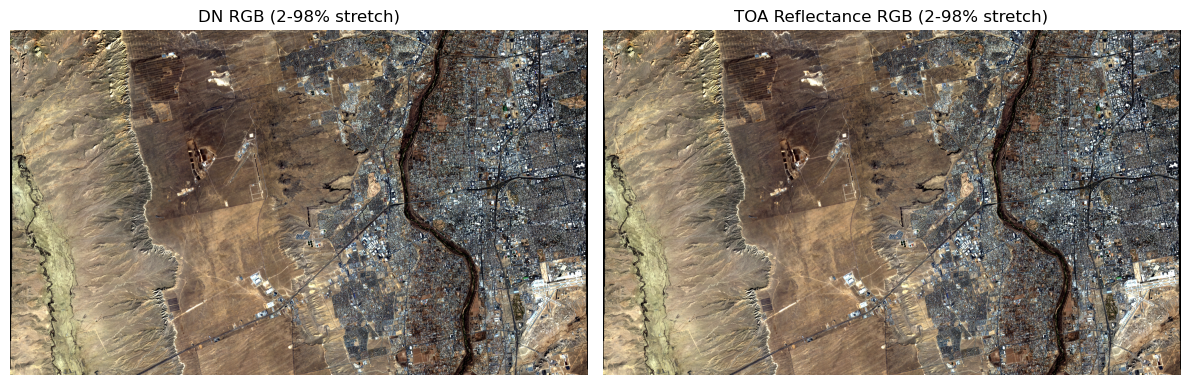

In [4]:
# Cell 3: quick display helpers and per-band stats (no installs)
import matplotlib.pyplot as plt
# assume previous cells ran and defined `dn`, `radiance`, `reflectance`, and `descriptions`
bands = dn.shape[0]
for i in range(bands):
    desc = descriptions[i] if descriptions else ''
    print(f'Band {i+1} ({desc}): DN min/max/mean={dn[i].min():.1f}/{dn[i].max():.1f}/{dn[i].mean():.1f}')
    print(f'  Radiance min/max/mean={radiance[i].min():.6f}/{radiance[i].max():.6f}/{radiance[i].mean():.6f}')
    print(f'  Reflectance min/max/mean={reflectance[i].min():.6f}/{reflectance[i].max():.6f}/{reflectance[i].mean():.6f}')

# Prepare RGB arrays for visualization: [B,G,R,NIR] -> RGB = [R,G,B]
dn_rgb = np.stack([dn[2], dn[1], dn[0]], axis=-1)
rho_rgb = np.stack([reflectance[2], reflectance[1], reflectance[0]], axis=-1)
dn_disp = np.stack([stretch_percentile(dn_rgb[..., c]) for c in range(3)], axis=-1)
rho_disp = np.stack([stretch_percentile(rho_rgb[..., c]) for c in range(3)], axis=-1)
plt.figure(figsize=(12,6))
plt.subplot(1,2,1); plt.imshow(dn_disp); plt.axis('off'); plt.title('DN RGB (2-98% stretch)')
plt.subplot(1,2,2); plt.imshow(rho_disp); plt.axis('off'); plt.title('TOA Reflectance RGB (2-98% stretch)')
plt.tight_layout(); plt.show()